# 08 · Q5 — Berapa tambahan harga dari produsen → pedagang besar → pasar?

**Keputusan yang didukung:** membeli langsung dari tingkat mana (produsen vs pedagang besar).

**Metode** (`src/analysis/margin.py`, `config.analisis.q5_margin`, `config.rantai_pasok`):
- Median **bulanan** per kota × komoditas × tingkat. Bulanan, bukan mingguan, karena harga produsen jarang diperbarui
  (±96% hari tidak berubah).
- Cakupan **utama**: kota yang punya ketiga tingkat dengan nama sama (sesuai brief). Cakupan **tambahan**: kota ↔
  kabupaten sentra di sekitarnya (PERLU_VERIFIKASI).
- Tambahan harga di pedagang besar = pedagang besar / produsen − 1; di pasar = pasar / pedagang besar − 1.
- Pasar modern dibandingkan dengan pasar tradisional di kota yang sama (brief: "pasar tradisional/modern").

In [1]:
import re
import sys
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path("..")
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

from src.analysis.common import load_cfg  # noqa: E402
cfg, lcfg = load_cfg()


def tampilkan_temuan(laporan: str) -> None:
    """Ambil bagian 'Temuan (bahasa dashboard)' dari laporan yang baru dibuat skrip, lalu tampilkan apa adanya."""
    teks = (ROOT / "reports" / laporan).read_text(encoding="utf-8")
    m = re.search(r"## Temuan \(bahasa dashboard\)\n(.*?)\n## ", teks, re.S)
    display(Markdown(m.group(1).strip() if m else "(bagian temuan tidak ditemukan)"))


def gambar(path) -> None:
    display(Image(filename=str(path)))

from src.analysis import margin as M
res = M.run(cfg)
res["per_kom"]

,kualitas,kota,produsen,pedagang_besar,tradisional,tambahan_pedagang_besar_pct,tambahan_eceran_pct,tambahan_total_pct,hemat_beli_produsen_pct,hemat_beli_pedagang_besar_pct,porsi_bulan_produsen_lebih_mahal,selisih_modern_vs_tradisional_pct,kota_modern
0,Cabai Rawit Merah,13.000,"33,675.000","40,062.500","48,125.000",0.163,0.201,0.462,0.316,0.167,0.348,0.686,21
1,Cabai Merah Keriting,10.000,"25,000.000","32,531.250","40,750.000",0.288,0.286,0.686,0.407,0.223,0.210,0.817,20
2,Bawang Merah Ukuran Sedang,11.000,"24,000.000","28,325.000","37,312.500",0.094,0.300,0.446,0.308,0.231,0.300,0.571,21
3,Daging Ayam Ras Segar,14.000,"27,462.500","31,000.000","35,725.000",0.152,0.132,0.271,0.213,0.116,0.311,0.200,22
4,Telur Ayam Ras Segar,11.000,"24,350.000","25,687.500","27,481.250",0.030,0.072,0.115,0.103,0.067,0.327,-0.008,23


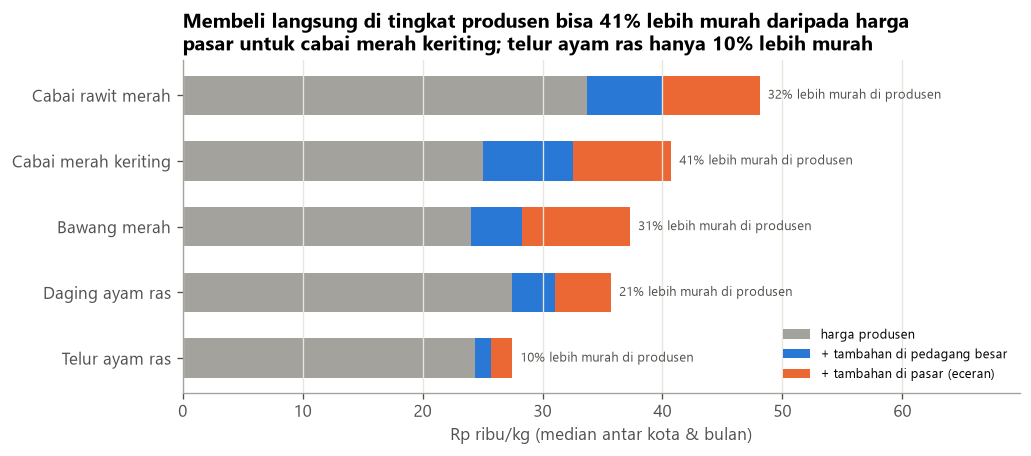

In [2]:
figs = M.figures(res)
gambar(figs["tingkat"])

## 1. Per kota
Kolom terakhir = porsi bulan ketika harga produsen tercatat **lebih mahal** daripada pedagang besar — tanda harga
produsen usang. Bulan seperti ini ditandai, tidak dibuang.

In [3]:
res["per_kota"].sort_values(["kualitas", "hemat_beli_produsen_pct"], ascending=[True, False])[
    ["kualitas", "kota", "produsen_dari", "cakupan", "bulan", "tambahan_pedagang_besar_pct", "tambahan_eceran_pct",
     "hemat_beli_produsen_pct", "porsi_bulan_produsen_lebih_mahal"]]

,kualitas,kota,produsen_dari,cakupan,bulan,tambahan_pedagang_besar_pct,tambahan_eceran_pct,hemat_beli_produsen_pct,porsi_bulan_produsen_lebih_mahal
24,Bawang Merah Ukuran Sedang,Kab. Jember,Kab. Jember,utama (kota sama),40,0.677,0.256,0.530,0.000
0,Bawang Merah Ukuran Sedang,Kota Cirebon,Kab. Cirebon,"tambahan (kabupaten sentra, PERLU_VERIFIKASI)",40,0.295,0.467,0.498,0.175
2,Bawang Merah Ukuran Sedang,Kota Malang,Kab. Malang,"tambahan (kabupaten sentra, PERLU_VERIFIKASI)",40,0.104,0.604,0.458,0.275
1,Bawang Merah Ukuran Sedang,Kota Kediri,Kab. Nganjuk,"tambahan (kabupaten sentra, PERLU_VERIFIKASI)",40,0.072,0.715,0.451,0.400
27,Bawang Merah Ukuran Sedang,Kota Tegal,Kota Tegal,utama (kota sama),40,0.333,0.300,0.424,0.100
3,Bawang Merah Ukuran Sedang,Kota Probolinggo,Kab. Probolinggo,"tambahan (kabupaten sentra, PERLU_VERIFIKASI)",40,0.180,0.223,0.308,0.175
28,Bawang Merah Ukuran Sedang,Kota Yogyakarta,Kota Yogyakarta,utama (kota sama),40,0.094,0.241,0.306,0.275
25,Bawang Merah Ukuran Sedang,Kota Semarang,Kota Semarang,utama (kota sama),40,0.086,0.210,0.281,0.250
4,Bawang Merah Ukuran Sedang,Kota Tasikmalaya,Kab. Garut,"tambahan (kabupaten sentra, PERLU_VERIFIKASI)",40,-0.073,0.387,0.241,0.525
23,Bawang Merah Ukuran Sedang,Kab. Cilacap,Kab. Cilacap,utama (kota sama),40,-0.088,0.313,0.174,0.625


## 2. Tambahan harga dari bulan ke bulan

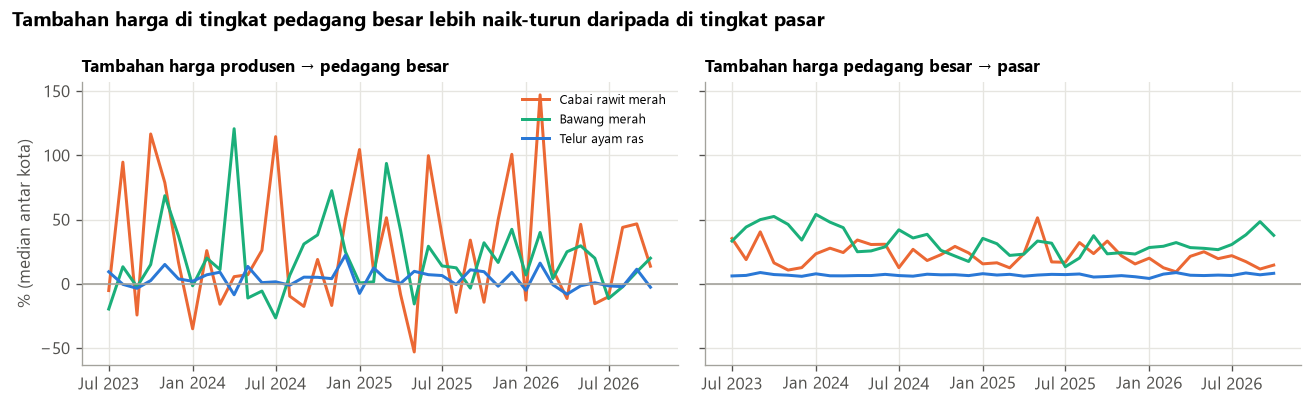

In [4]:
gambar(figs["tren"])

## 3. Pasar modern vs pasar tradisional

In [5]:
res["per_kom"][["kualitas", "kota_modern", "selisih_modern_vs_tradisional_pct"]]

,kualitas,kota_modern,selisih_modern_vs_tradisional_pct
0,Cabai Rawit Merah,21,0.686
1,Cabai Merah Keriting,20,0.817
2,Bawang Merah Ukuran Sedang,21,0.571
3,Daging Ayam Ras Segar,22,0.200
4,Telur Ayam Ras Segar,23,-0.008


### Temuan (bahasa dashboard)
Kalimat di bawah **tidak diketik tangan**: diambil dari laporan yang baru saja dibuat skrip, sehingga selalu sama dengan
angka di tabel di atas.

In [6]:
M.write_summary(res, figs)
tampilkan_temuan("q5_margin.md")

**Membeli langsung di tingkat produsen bisa 41% lebih murah daripada harga pasar untuk
cabai merah keriting** (median antar kota; harga produsen Rp 25.000/kg vs pasar Rp 40.750/kg).
Untuk telur ayam ras selisihnya hanya 10%.
Dibanding membeli di pedagang besar, membeli di produsen paling menghemat untuk cabai merah keriting, cabai rawit merah, daging ayam ras (tambahan harga di pedagang besar
29%, 16%, 15%); untuk bawang merah, telur ayam ras tambahan di pedagang besar hanya 9%, 3%.
Tindakan: jajaki pembelian langsung dari petani/pengepul di sentra untuk cabai merah keriting, cabai rawit merah, daging ayam ras; untuk bawang merah, telur ayam ras pedagang besar sudah dekat
dengan harga produsen.
Catatan: harga produsen jarang diperbarui, sehingga pada sebagian bulan tercatat lebih mahal daripada pedagang besar
(kolom terakhir). Angka ini perkiraan kasar.